# Menu Profit Simulator: analysis

A synthetic 30-item bistro. The question: **which menu items and operational changes improve profit without hurting demand, and how sure can we be?**

Everything here is computed by the functions in `sim/` (the same model the dashboard runs in JavaScript) on data queried from DuckDB. The notebook defines no formulas. The data is synthetic and the demand truth is authored, so the validation section shows where the method works and where it fails, not real-world accuracy.

**Elasticity is an assumption.** Wherever a number depends on it, it is shown as a range across a low (-0.5), medium (-1.0) and high (-1.8) band.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from etl.warehouse import get_connection
from etl.baseline import baseline_from_warehouse
from sim.scenarios import run_scenario
from sim.matrix import classify
from sim.experiments import build_backlog

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 140
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
CLASS_STYLE = {"Star": ("#2a78d6", "o"), "Plowhorse": ("#eb6834", "s"), "Puzzle": ("#1baf7a", "D"), "Dog": ("#d9467e", "^")}

con = get_connection(read_only=True)
baseline = baseline_from_warehouse(con)
BEEF = ["ribeye", "sirloin", "short_rib", "ground_beef", "shaved_beef"]
print(len(baseline["items"]), "items, trailing", baseline["window_weeks"], "weeks")

30 items, trailing 12 weeks


## 1. Baseline margins

Item cost is the recipe quantity times the latest ingredient cost (SQL view `v_item_cm`). Contribution margin (CM) is price minus that cost, in dollars per unit.

In [2]:
items = con.execute("SELECT * FROM v_item_cm ORDER BY weekly_contribution_profit DESC").df()
items[["name", "category", "price", "unit_cost", "cm", "food_cost_pct", "weekly_units", "weekly_contribution_profit"]].head(10)

,name,category,price,unit_cost,cm,food_cost_pct,weekly_units,weekly_contribution_profit
0,Chicken Parm,Entrees,23.50,5.16,18.34,0.22,98.83,"1,812.25"
1,Classic Burger,Burgers and sandwiches,16.00,6.26,9.74,0.39,132.00,"1,285.53"
2,Fish and Chips,Entrees,20.00,6.28,13.72,0.31,92.08,"1,263.09"
3,Bacon Cheeseburger,Burgers and sandwiches,17.00,7.27,9.73,0.43,111.83,"1,087.65"
4,Spaghetti Bolognese,Pasta and bowls,19.00,4.92,14.08,0.26,74.92,"1,054.47"
5,Chicken Alfredo,Pasta and bowls,20.00,5.42,14.58,0.27,70.33,"1,025.80"
6,Ribeye,Entrees,38.00,14.99,23.01,0.39,36.50,839.75
7,Chicken Sandwich,Burgers and sandwiches,14.00,3.73,10.27,0.27,77.75,798.44
8,Salmon,Entrees,28.50,9.47,19.03,0.33,38.75,737.30
9,Loaded Nachos,Starters,13.00,4.90,8.10,0.38,88.17,714.43


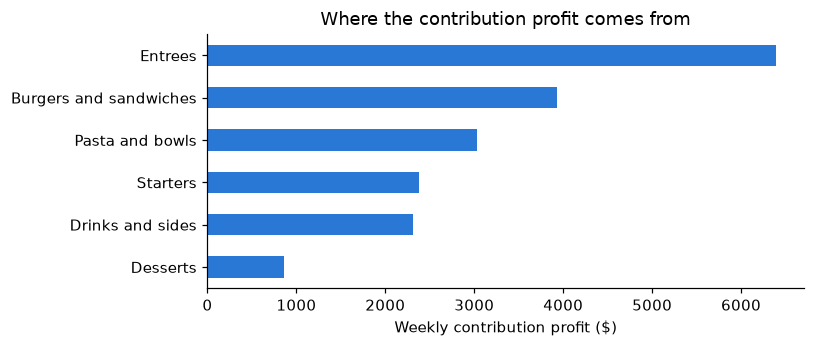

In [3]:
from etl.run_queries import parse_queries
queries = parse_queries((ROOT / "sql" / "analysis_queries.sql").read_text())
cat = con.execute(queries["category_summary"]).df()
ax = cat.set_index("category")["weekly_contribution_profit"].sort_values().plot.barh(color="#2a78d6", figsize=(7, 3))
ax.set_xlabel("Weekly contribution profit ($)"); ax.set_ylabel(""); ax.set_title("Where the contribution profit comes from"); plt.show()

## 2. The menu engineering matrix

Each item is compared with its own category: popular if its share of the category's units is at least 70% of an equal share, high margin if its CM is at or above the category's unit-weighted average. Four to seven items per category makes the thresholds noisy.

class
Star         11
Plowhorse     8
Dog           6
Puzzle        5


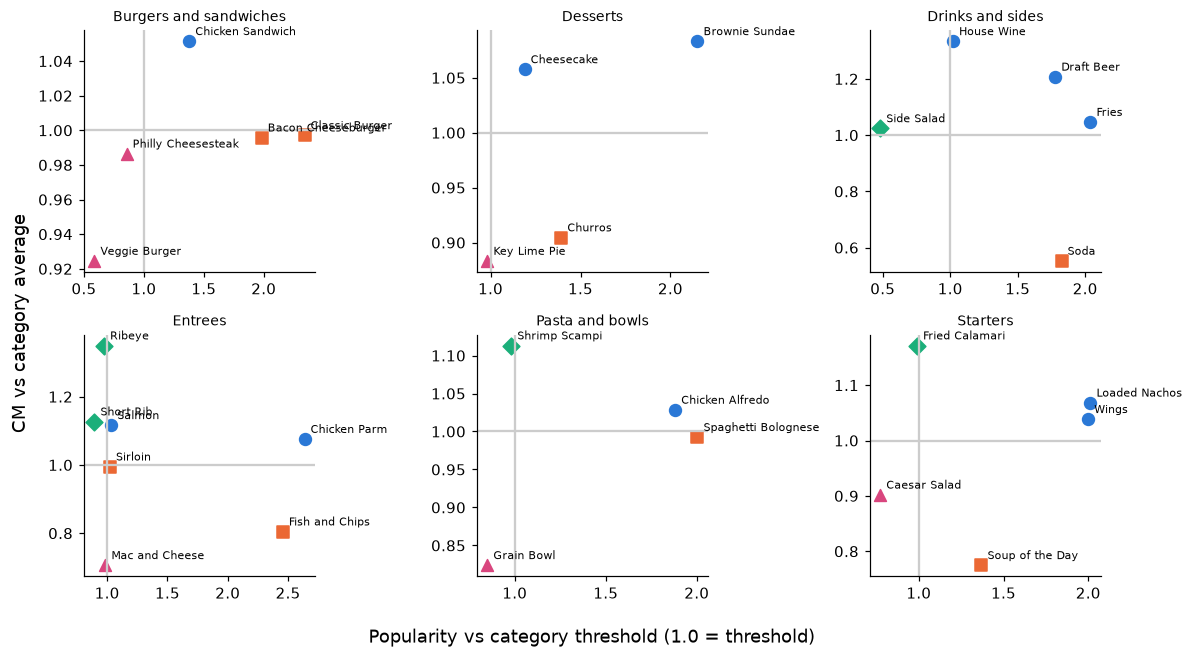

In [4]:
rows = items.rename(columns={"window_units": "units"})[["item_id", "name", "category", "units", "cm"]].to_dict("records")
base_matrix = classify(rows, "category")
items["class"] = items["item_id"].map({i: r["class"] for i, r in base_matrix["items"].items()})
print(items["class"].value_counts().to_string())
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=False)
for ax, (category, grp) in zip(axes.ravel(), items.groupby("category")):
    t = base_matrix["thresholds"][category]
    for _, r in grp.iterrows():
        color, mk = CLASS_STYLE[r["class"]]
        share = base_matrix["items"][r["item_id"]]["share"]
        ax.scatter(share / t["popularity_threshold"], r["cm"] / t["margin_threshold"], c=color, marker=mk, s=60)
        ax.annotate(r["name"], (share / t["popularity_threshold"], r["cm"] / t["margin_threshold"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.axvline(1, color="#ccc"); ax.axhline(1, color="#ccc"); ax.set_title(category, fontsize=9)
fig.supxlabel("Popularity vs category threshold (1.0 = threshold)"); fig.supylabel("CM vs category average"); plt.tight_layout(); plt.show()

## 3. A beef cost shock

Beef +20% flows through the recipes of the seven items that use it. With no price change there is no demand response, so the result does not depend on elasticity and the three bands agree.

In [5]:
shock = run_scenario(baseline, {"cost_shock": {i: 0.20 for i in BEEF}})
hit = pd.DataFrame([
    {"item": v["name"], "category": v["category"], "baseline CM": v["baseline"]["cm"], "shocked CM": v["by_band"]["medium"]["cm"],
     "weekly profit change": v["by_band"]["medium"]["profit_change"], "class": f'{v["matrix"]["baseline_class"]} -> {v["matrix"]["scenario_class"]}'}
    for v in shock["items"].values() if v["by_band"]["medium"]["profit_change"] != 0
]).sort_values("weekly profit change")
print("Menu weekly profit change:", {b: round(t["profit_change"]) for b, t in shock["total"]["by_band"].items()})
hit

Menu weekly profit change: {'low': -561, 'medium': -561, 'high': -561}


,item,category,baseline CM,shocked CM,weekly profit change,class
2,Classic Burger,Burgers and sandwiches,9.74,8.80,-123.89,Plowhorse -> Plowhorse
0,Bacon Cheeseburger,Burgers and sandwiches,9.73,8.79,-104.96,Plowhorse -> Plowhorse
4,Ribeye,Entrees,23.01,20.30,-98.64,Puzzle -> Puzzle
6,Sirloin,Entrees,16.96,15.03,-73.82,Plowhorse -> Plowhorse
5,Short Rib,Entrees,19.21,17.02,-73.47,Puzzle -> Puzzle
3,Philly Cheesesteak,Burgers and sandwiches,9.64,8.71,-44.44,Dog -> Dog
1,Spaghetti Bolognese,Pasta and bowls,14.08,13.51,-42.19,Plowhorse -> Plowhorse


## 4. Price scenarios with elasticity bands

A price rise on one item, +5%. The **break-even elasticity** is the demand response at which the change leaves that item's profit unchanged; a rise pays off if demand is *less* elastic than that. The hatched band is the assumed elasticity range. When the break-even sits inside the band, the verdict depends on an assumption nobody has measured.

In [6]:
scen = run_scenario(baseline, {"price_change": {i: 0.05 for i in ["ribeye", "classic_burger", "salmon", "fries", "wings", "chicken_parm"]}})
tests = pd.DataFrame([
    {"item": v["name"], "break-even elasticity": v["price_test"]["break_even_elasticity"], "break-even drop": v["price_test"]["break_even_drop"],
     "predicted drop (medium)": v["price_test"]["by_band"]["medium"]["predicted_drop"], "verdict": v["price_test"]["verdict"],
     "weekly change low band": v["by_band"]["low"]["profit_change"], "medium": v["by_band"]["medium"]["profit_change"], "high band": v["by_band"]["high"]["profit_change"]}
    for v in scen["items"].values() if v["price_test"]
])
tests

,item,break-even elasticity,break-even drop,predicted drop (medium),verdict,weekly change low band,medium,high band
0,Chicken Parm,-1.27,0.06,0.05,pays off only if demand is less elastic than -...,72.25,29.42,-36.96
1,Classic Burger,-1.62,0.08,0.05,pays off only if demand is less elastic than -...,72.07,39.36,-11.36
2,Fries,-1.42,0.07,0.05,pays off only if demand is less elastic than -...,31.90,14.46,-12.59
3,Ribeye,-1.63,0.08,0.05,pays off only if demand is less elastic than -...,50.03,31.18,1.96
4,Salmon,-1.48,0.07,0.05,pays off only if demand is less elastic than -...,38.34,21.87,-3.65
5,Wings,-1.62,0.08,0.05,pays off only if demand is less elastic than -...,38.93,21.36,-5.87


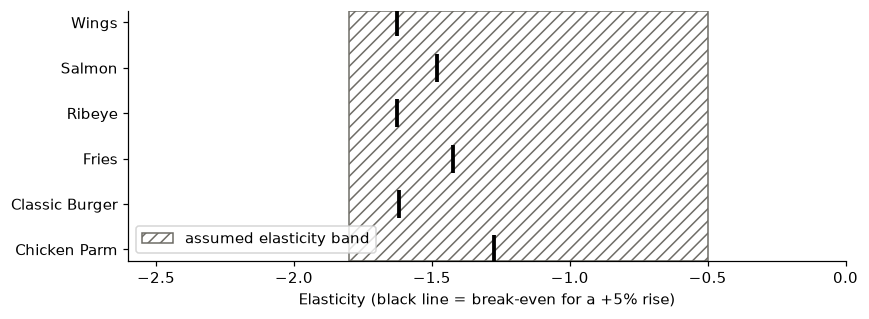

Menu weekly profit change across the bands: +23 to +330


In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
lo, hi = min(scen["bands"].values()), max(scen["bands"].values())
ax.axvspan(lo, hi, facecolor="none", hatch="///", edgecolor="#6f6d67", label="assumed elasticity band")
for k, (_, r) in enumerate(tests.iterrows()):
    ax.plot([r["break-even elasticity"]], [k], "|", color="black", markersize=18, mew=2.5)
ax.set_yticks(range(len(tests))); ax.set_yticklabels(tests["item"]); ax.set_xlim(-2.6, 0)
ax.set_xlabel("Elasticity (black line = break-even for a +5% rise)"); ax.legend(loc="lower left"); plt.tight_layout(); plt.show()
t = scen["total"]["profit_change_range"]; print(f"Menu weekly profit change across the bands: {t['low']:+,.0f} to {t['high']:+,.0f}")

## 5. The substitution slider

Substitution (the share of lost buyers who switch to a similar dish) is also an assumption: the research found no usable within-menu rate. It cushions a price rise on a dish that has close neighbours.

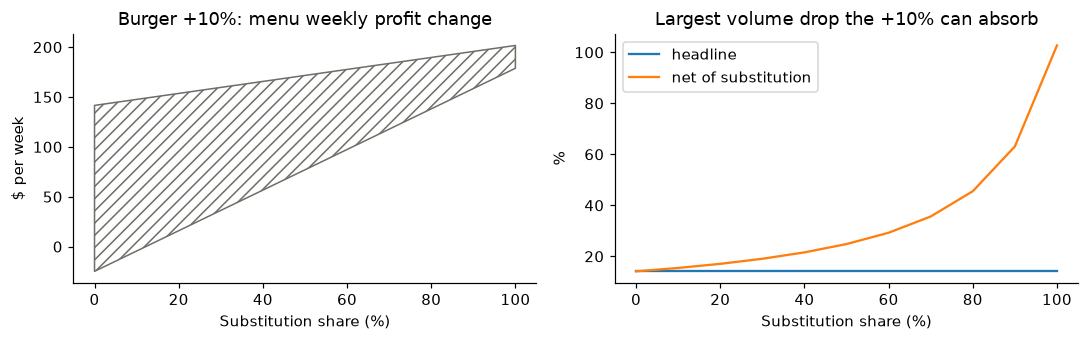

In [8]:
rows = []
for s in range(0, 101, 10):
    r = run_scenario(baseline, {"price_change": {"classic_burger": 0.10}, "substitution": s / 100})
    t = r["items"]["classic_burger"]["price_test"]
    rows.append({"substitution %": s, "menu change, low band": r["total"]["by_band"]["low"]["profit_change"],
                 "menu change, high band": r["total"]["by_band"]["high"]["profit_change"],
                 "break-even drop (no substitution)": t["break_even_drop"], "break-even drop (net)": t["break_even_drop_net"]})
sub = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].fill_between(sub["substitution %"], sub["menu change, high band"], sub["menu change, low band"], facecolor="none", hatch="///", edgecolor="#6f6d67")
axes[0].set_title("Burger +10%: menu weekly profit change"); axes[0].set_xlabel("Substitution share (%)"); axes[0].set_ylabel("$ per week")
axes[1].plot(sub["substitution %"], sub["break-even drop (no substitution)"] * 100, label="headline")
axes[1].plot(sub["substitution %"], sub["break-even drop (net)"] * 100, label="net of substitution")
axes[1].set_title("Largest volume drop the +10% can absorb"); axes[1].set_xlabel("Substitution share (%)"); axes[1].set_ylabel("%"); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. The experiment backlog

Elasticity is assumed, so the plan is to measure it. Each candidate test is scored by stake, how uncertain the decision is, feasibility and risk. Duration comes from the noise in daily profit, assuming one-day blocks and one block of carryover. **At this restaurant's noise level, nothing fits in 12 weeks.** The table shows the shortest tests; the chart shows how a bigger price step shortens the test.

In [9]:
res = run_scenario(baseline, {"price_change": {"ribeye": 0.05, "classic_burger": 0.05}})
bl = build_backlog(baseline, res)
print(len(bl["feasible_now"]), "feasible now;", len(bl["needs_pooling"]), "need pooling or a larger effect")
pd.DataFrame([{"rank": e["rank"], "target": e["target_name"], "type": e["type"], "evidence": e["evidence"], "weeks": e["duration_weeks"],
               "score": e["score"], **e["factors"]} for e in bl["needs_pooling"][:10]])

0 feasible now; 34 need pooling or a larger effect


,rank,target,type,evidence,weeks,score,stake,decision_uncertainty,feasibility,normalised_risk
0,1,Fish and Chips,Price switchback test,method-backed,464,1.26,"3,090.03",0.80,0.00,0.01
1,2,Spaghetti Bolognese,Price switchback test,method-backed,497,1.00,"2,290.23",0.92,0.00,0.01
2,3,Classic Burger,Price switchback test,method-backed,611,0.71,"3,747.84",0.48,0.00,0.00
3,4,Bacon Cheeseburger,Price switchback test,method-backed,287,0.69,"3,460.87",0.24,0.00,0.00
4,5,Grain Bowl,Price switchback test,method-backed,441,0.40,824.07,0.90,0.00,0.01
5,6,Mac and Cheese,Price switchback test,method-backed,588,0.35,941.84,0.93,0.00,0.01
6,7,Soda,Price switchback test,method-backed,478,0.32,807.54,0.79,0.00,0.01
7,8,Sirloin,Price switchback test,method-backed,956,0.22,"1,908.72",0.46,0.00,0.00
8,9,Soup of the Day,Price switchback test,method-backed,830,0.20,776.00,0.91,0.00,0.01
9,10,Churros,Price switchback test,method-backed,551,0.16,443.89,0.85,0.00,0.01


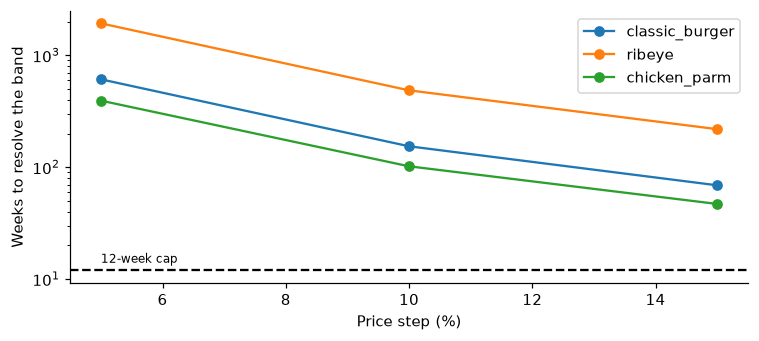

In [10]:
steps = [0.05, 0.10, 0.15]
weeks = {}
for item in ["classic_burger", "ribeye", "chicken_parm"]:
    ws = []
    for step in steps:
        entries = build_backlog(baseline, run_scenario(baseline, {"price_change": {item: step}}))["all"]
        ws.append(next(e["duration_weeks"] for e in entries if e["target"] == item and e["type"] == "Price switchback test"))
    weeks[item] = ws
fig, ax = plt.subplots(figsize=(7, 3.2))
for item, ws in weeks.items():
    ax.plot([s * 100 for s in steps], ws, marker="o", label=item)
ax.axhline(12, color="black", linestyle="--"); ax.text(5, 14, "12-week cap", fontsize=8)
ax.set_yscale("log"); ax.set_xlabel("Price step (%)"); ax.set_ylabel("Weeks to resolve the band"); ax.legend(); plt.tight_layout(); plt.show()

In [11]:
e = bl["needs_pooling"][0]
print(e["target_name"], "|", e["type"], "|", e["evidence"])
print("Hypothesis:", e["hypothesis"]); print("Decision:  ", e["decision_rule"])
print("Guardrails:", [(g["name"], g["stop_if_down_pct"]) for g in e["guardrails"]["metrics"]], "(" + e["guardrails"]["label"] + ")")
for k, v in e["stop_rules"].items(): print(f"Stop rule ({k}):", v)

Fish and Chips | Price switchback test | method-backed
Hypothesis: Demand for Fish and Chips is less elastic than -1.44, so a +5% price change raises profit.
Decision:   If the measured elasticity is above -1.44, roll out the change; otherwise revert.
Guardrails: [('Total units sold (traffic proxy)', 3.0), ('Menu-total contribution profit per week', 2.0), ('Same-category units (cannibalization)', None)] (policy choice, not evidence)
Stop rule (harm): Stop if a guardrail is beyond its threshold at two consecutive weekly looks, after at least one full week of each arm.
Stop rule (cap): Stop at the planned duration or the 12-week cap, whichever comes first.
Stop rule (success): No early success stop. Read the result only at the planned end with the design-matched randomization test.


## 7. Validation against the authored truth

The generator authored each item's true elasticity and substitution. `sim/validation.py` is the only code that reads them. These results come from `validation_results.json` and `validation_recovery.json`, committed snapshots. There are no pass/fail bounds on any finding.

In [12]:
val = json.load(open(ROOT / "validation_results.json")); rec = json.load(open(ROOT / "validation_recovery.json"))
bh, sc, nh = val["band_hit_rate"], val["scenario_scorecard"], val["naive_history"]
pd.DataFrame([
    ["True elasticity inside the band", f'{bh["rate"]:.0%}', f'{bh["inside_band"]} of {bh["items"]} items; misses are all in Drinks and sides'],
    ["Profit range covers the truth", f'{sc["profit_range_coverage"]["rate"]:.0%}', f'{sc["scenarios"]} scenarios (+5% and +10% on each item); misses are all on the optimistic side'],
    ["Medium-band headline has the right sign", f'{sc["verdicts"]["medium_band_sign_accuracy"]:.0%}', f'{sc["verdicts"]["medium_band_says_pays_when_truth_loses"]} cases say "pays off" when the truth loses'],
    ["Verdicts that are decisive", f'{sc["verdicts"]["pays_off_under_all_bands"] + sc["verdicts"]["loses_under_all_bands"]} of {sc["verdicts"]["total"]}', "the break-even usually sits inside a band this wide"],
    ["Naive before/after, median abs error", f'{nh["median_abs_error"]:.2f}', f'{nh["events"]} historical price changes; {nh["wrong_sign_share"]:.0%} have the wrong sign'],
    ["Switchback recovery at the 12-week cap", f'{rec["mean_decision_accuracy"]["at_cap"]:.0%}', f'{rec["reps"]} replications per entry; about a coin flip'],
    ["Switchback recovery at the powered duration", f'{rec["mean_decision_accuracy"]["planned_duration"]:.0%}', "durations of years, so not achievable in practice"],
], columns=["Check", "Result", "Note"])

,Check,Result,Note
0,True elasticity inside the band,87%,26 of 30 items; misses are all in Drinks and s...
1,Profit range covers the truth,72%,60 scenarios (+5% and +10% on each item); miss...
2,Medium-band headline has the right sign,90%,"6 cases say ""pays off"" when the truth loses"
3,Verdicts that are decisive,0 of 60,the break-even usually sits inside a band this...
4,"Naive before/after, median abs error",0.87,9 historical price changes; 22% have the wrong...
5,Switchback recovery at the 12-week cap,60%,200 replications per entry; about a coin flip
6,Switchback recovery at the powered duration,83%,"durations of years, so not achievable in practice"


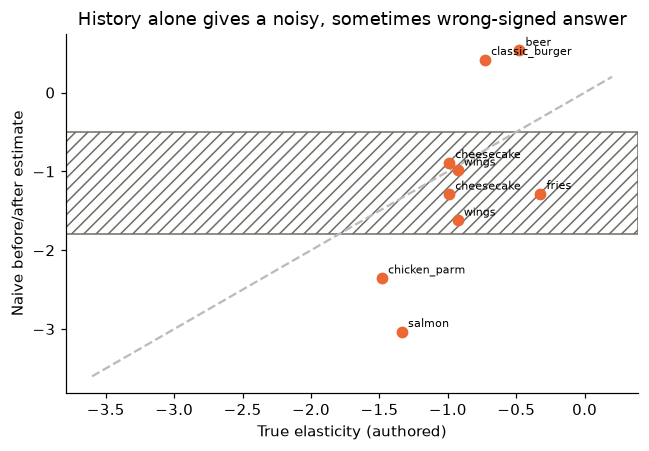

In [13]:
ev = pd.DataFrame(nh["detail"])
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.axhspan(-1.8, -0.5, facecolor="none", hatch="///", edgecolor="#6f6d67")
ax.plot([-3.6, 0.2], [-3.6, 0.2], color="#bbb", linestyle="--")
ax.scatter(ev["true"], ev["naive"], c="#eb6834", s=45, zorder=3)
for _, r in ev.iterrows(): ax.annotate(r["item"], (r["true"], r["naive"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("True elasticity (authored)"); ax.set_ylabel("Naive before/after estimate"); ax.set_title("History alone gives a noisy, sometimes wrong-signed answer")
plt.tight_layout(); plt.show()

## Takeaways

* Margins and the matrix are descriptive and solid; they come straight from recipes, costs and sales.
* A cost shock alone is unambiguous. A price change is not: its sign usually depends on an elasticity nobody has measured, so the output is a range plus a break-even.
* Price history is confounded and gives a poor estimate (median error 0.87, two of nine with the wrong sign), which is why the project recommends experiments.
* At one restaurant's noise level, no single-item price test fits in a quarter; pooling a category with a larger price step gets close (about 16 weeks for the entrees at +15%). The honest options are larger effects, pooled items or longer tests.

Limitations are listed in the README: synthetic data and authored truth, assumed elasticity bands, single-pass substitution, no waste or yield, total units as a traffic proxy, assumed carryover and noise, policy-choice guardrails, weak evidence for menu-design and portion tests.